In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
df = pd.read_csv("uber.csv")

print("First five records:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

First five records:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



Dataset Shape: (200000, 9)

Column Names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [11]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip().str.lower()

# Remove unnecessary index column if present
df = df.loc[:, ~df.columns.str.contains('^unnamed')]

# Check required columns
print("Available columns:", df.columns.tolist())

# Remove duplicates
df = df.drop_duplicates()

# Convert datetime column
if 'pickup_datetime' in df.columns:

    df['pickup_datetime'] = pd.to_datetime(
        df['pickup_datetime'], errors='coerce', utc=True
    )

    df = df.dropna(subset=['pickup_datetime'])

    # Extract date and time features
    df['hour'] = df['pickup_datetime'].dt.hour
    df['day'] = df['pickup_datetime'].dt.day
    df['month'] = df['pickup_datetime'].dt.month
    df['year'] = df['pickup_datetime'].dt.year

    df.drop(columns=['pickup_datetime'], inplace=True)

# Drop key column
df.drop(columns=['key'], errors='ignore', inplace=True)

# Remove missing values
df = df.dropna()

print("Dataset after preprocessing:")
display(df.head())

print("Shape:", df.shape)

Available columns: ['key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
Dataset after preprocessing:


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014


Shape: (199999, 10)


In [12]:
print("Statistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Statistical Summary:


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year
count,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543,13.491387,15.704739,6.281791,2011.742434
std,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995,6.515505,8.687377,3.438933,1.856400
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000,0.000000,1.000000,1.000000,2009.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000,9.000000,8.000000,3.000000,2010.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000,14.000000,16.000000,6.000000,2012.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000,19.000000,23.000000,9.000000,2013.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000,23.000000,31.000000,12.000000,2015.000000



Missing Values:
fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
year                 0
dtype: int64


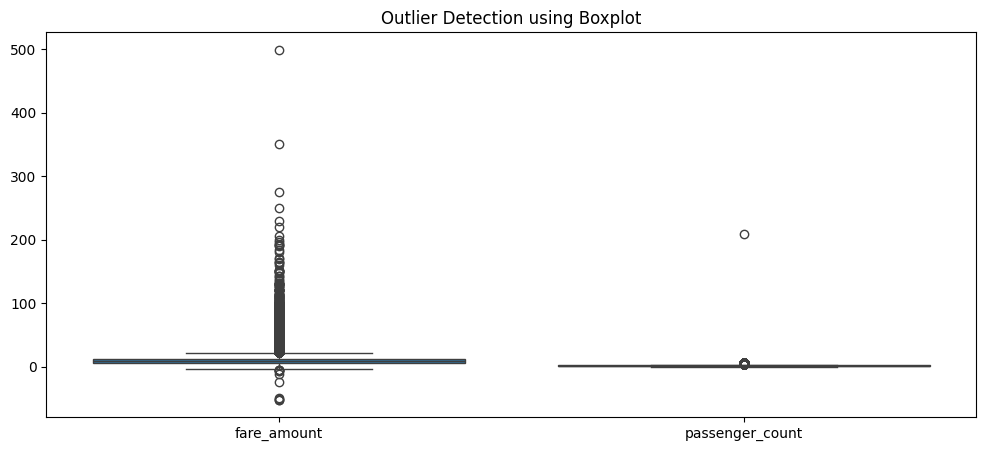

In [13]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df[['fare_amount', 'passenger_count']])

plt.title("Outlier Detection using Boxplot")
plt.show()

In [14]:
# Remove invalid fare amounts
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 500)]

# Remove invalid passenger counts
df = df[(df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)]

# Remove invalid geographical coordinates
df = df[
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180) &
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90)
]

# IQR method for fare amount
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (182136, 10)


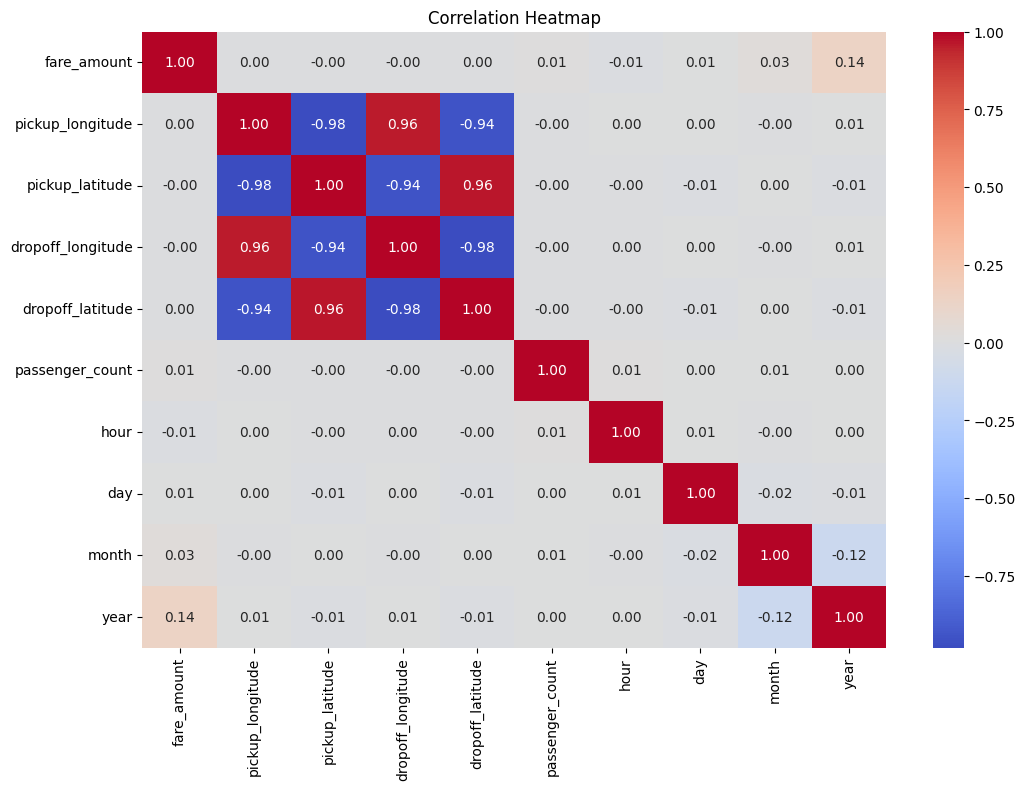

In [15]:
plt.figure(figsize=(12, 8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [16]:
# Features
X = df.drop('fare_amount', axis=1)

# Target
y = df['fare_amount']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (145708, 9)
Testing data: (36428, 9)


In [17]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_test)

# Evaluate
lr_r2 = r2_score(y_test, lr_pred)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print("Linear Regression Results")
print("R2 Score:", lr_r2)
print("RMSE:", lr_rmse)

Linear Regression Results
R2 Score: 0.019088568246473314
RMSE: 4.085366406102818


In [18]:
# Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Evaluate
rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest Regression Results")
print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)

Random Forest Regression Results
R2 Score: 0.7520574162655922
RMSE: 2.053958557749442


In [19]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'R2 Score': [lr_r2, rf_r2],
    'RMSE': [lr_rmse, rf_rmse]
})

print("Model Comparison:")
display(results)

Model Comparison:


,Model,R2 Score,RMSE
0,Linear Regression,0.019089,4.085366
1,Random Forest Regression,0.752057,2.053959


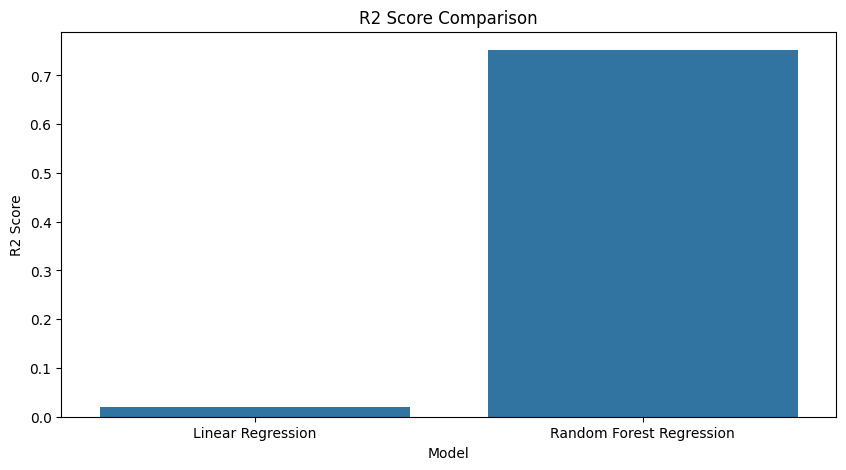

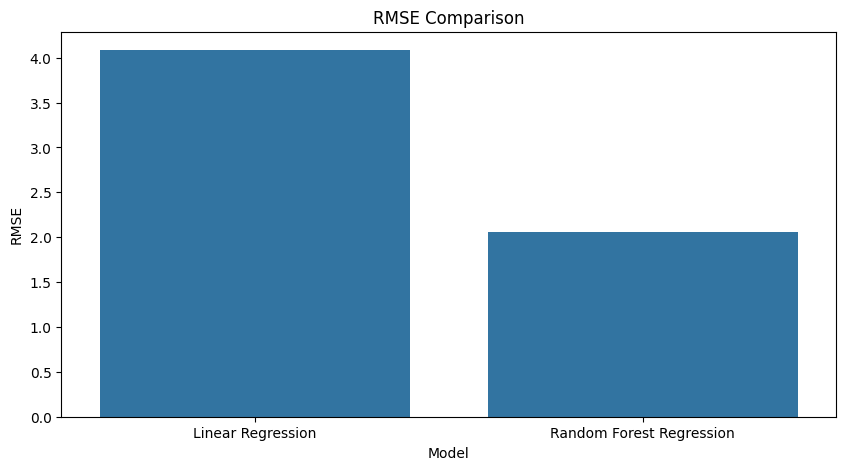

In [20]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results, x='Model', y='R2 Score')

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.show()


plt.figure(figsize=(10, 5))

sns.barplot(data=results, x='Model', y='RMSE')

plt.title("RMSE Comparison")
plt.ylabel("RMSE")
plt.show()

In [21]:
if rf_r2 > lr_r2 and rf_rmse < lr_rmse:
    print("Random Forest Regression performs better.")
elif lr_r2 > rf_r2 and lr_rmse < rf_rmse:
    print("Linear Regression performs better.")
else:
    print("Compare both R2 and RMSE values to select the better model.")

print("\nFinal Results:")
print("Linear Regression R2:", lr_r2)
print("Linear Regression RMSE:", lr_rmse)

print("Random Forest R2:", rf_r2)
print("Random Forest RMSE:", rf_rmse)

Random Forest Regression performs better.

Final Results:
Linear Regression R2: 0.019088568246473314
Linear Regression RMSE: 4.085366406102818
Random Forest R2: 0.7520574162655922
Random Forest RMSE: 2.053958557749442
